# 01 - Dataset exploration

Use this notebook to inspect the 440-track manifest, class balance, source metadata, audio durations, and sample waveforms.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import librosa
import librosa.display
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
DATASET_MANIFEST = ROOT / 'data' / 'processed' / 'dataset_manifest.csv'
RAW_AUDIO = ROOT / 'data' / 'raw'
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_colwidth', 80)

In [2]:
manifest = pd.read_csv(DATASET_MANIFEST)
manifest.head()

,track_id,label,audio_url,source,license,source_revision,sha256,download_error
0,000657be-98fe-4f4c-9b00-461ea2079938,ai_generated,https://datasets-server.huggingface.co/cached-assets/ai-music4you/ai-generat...,https://huggingface.co/datasets/ai-music4you/ai-generated-songs,See dataset card and Suno source terms; local research use only,cf62db6dc87ca2cbab2ed5e1170bfa727a632013,7157606179bc962ddd127718ba3571fc28e45d2729327bf9f6249715c23d9355,NaN
1,0010ccca-4088-4975-9bd4-9b2985851f32,ai_generated,https://datasets-server.huggingface.co/cached-assets/ai-music4you/ai-generat...,https://huggingface.co/datasets/ai-music4you/ai-generated-songs,See dataset card and Suno source terms; local research use only,cf62db6dc87ca2cbab2ed5e1170bfa727a632013,2cd346862f88c56207c4d870c55413d8c6dccd54d446c42861d53634f927550d,NaN
2,0017a515-cb61-4ffc-8336-f4ef8cd6668f,ai_generated,https://datasets-server.huggingface.co/cached-assets/ai-music4you/ai-generat...,https://huggingface.co/datasets/ai-music4you/ai-generated-songs,See dataset card and Suno source terms; local research use only,cf62db6dc87ca2cbab2ed5e1170bfa727a632013,c978f487e207f6192c177d9b4b0fb33047a338608c133c4613dbf6e8ea3dd805,NaN
3,00206f12-4f96-45f2-bd12-45240b3789ab,ai_generated,https://datasets-server.huggingface.co/cached-assets/ai-music4you/ai-generat...,https://huggingface.co/datasets/ai-music4you/ai-generated-songs,See dataset card and Suno source terms; local research use only,cf62db6dc87ca2cbab2ed5e1170bfa727a632013,88a455d42fe56ec182a91b9cb745fbd5e88d85091a722409a2e352d7c44de51a,NaN
4,002fb2bd-0d98-455b-90c0-b9db06838764,ai_generated,https://datasets-server.huggingface.co/cached-assets/ai-music4you/ai-generat...,https://huggingface.co/datasets/ai-music4you/ai-generated-songs,See dataset card and Suno source terms; local research use only,cf62db6dc87ca2cbab2ed5e1170bfa727a632013,8ebb65621eed3c474ae33c0e181749eee3502c41e34ffae6d455f27343561021,NaN


In [3]:
display(manifest.shape)
display(manifest['label'].value_counts())
display(manifest.groupby('label').size().to_frame('track_count'))
display(manifest[['label', 'source', 'license']].head(10))

(440, 8)

label
ai_generated    220
human           220
Name: count, dtype: int64

,track_count
label,
ai_generated,220
human,220


,label,source,license
0,ai_generated,https://huggingface.co/datasets/ai-music4you/ai-generated-songs,See dataset card and Suno source terms; local research use only
1,ai_generated,https://huggingface.co/datasets/ai-music4you/ai-generated-songs,See dataset card and Suno source terms; local research use only
2,ai_generated,https://huggingface.co/datasets/ai-music4you/ai-generated-songs,See dataset card and Suno source terms; local research use only
3,ai_generated,https://huggingface.co/datasets/ai-music4you/ai-generated-songs,See dataset card and Suno source terms; local research use only
4,ai_generated,https://huggingface.co/datasets/ai-music4you/ai-generated-songs,See dataset card and Suno source terms; local research use only
5,ai_generated,https://huggingface.co/datasets/ai-music4you/ai-generated-songs,See dataset card and Suno source terms; local research use only
6,ai_generated,https://huggingface.co/datasets/ai-music4you/ai-generated-songs,See dataset card and Suno source terms; local research use only
7,ai_generated,https://huggingface.co/datasets/ai-music4you/ai-generated-songs,See dataset card and Suno source terms; local research use only
8,ai_generated,https://huggingface.co/datasets/ai-music4you/ai-generated-songs,See dataset card and Suno source terms; local research use only
9,ai_generated,https://huggingface.co/datasets/ai-music4you/ai-generated-songs,See dataset card and Suno source terms; local research use only


In [4]:
manifest['local_path'] = manifest.apply(
    lambda row: RAW_AUDIO / row['label'] / f"{row['track_id']}.mp3", axis=1
)
manifest['exists'] = manifest['local_path'].map(Path.exists)
manifest.groupby(['label', 'exists']).size().to_frame('count')

,,count
label,exists,
ai_generated,True,220
human,True,220


000657be-98fe-4f4c-9b00-461ea2079938 ai_generated 48000 1440000 30.0


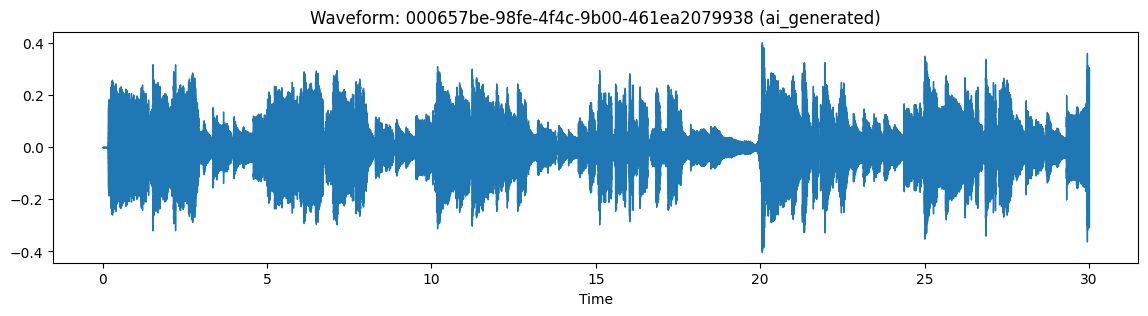

In [5]:
sample = manifest[manifest['exists']].iloc[0]
audio, sample_rate = librosa.load(sample['local_path'], sr=None, mono=True, duration=30)
print(sample['track_id'], sample['label'], sample_rate, len(audio), len(audio) / sample_rate)
fig, ax = plt.subplots(figsize=(14, 3))
librosa.display.waveshow(audio, sr=sample_rate, ax=ax)
ax.set_title(f"Waveform: {sample['track_id']} ({sample['label']})")
plt.show()